In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
NumPy version: 2.1.3


In [2]:
# Load MNIST dataset

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


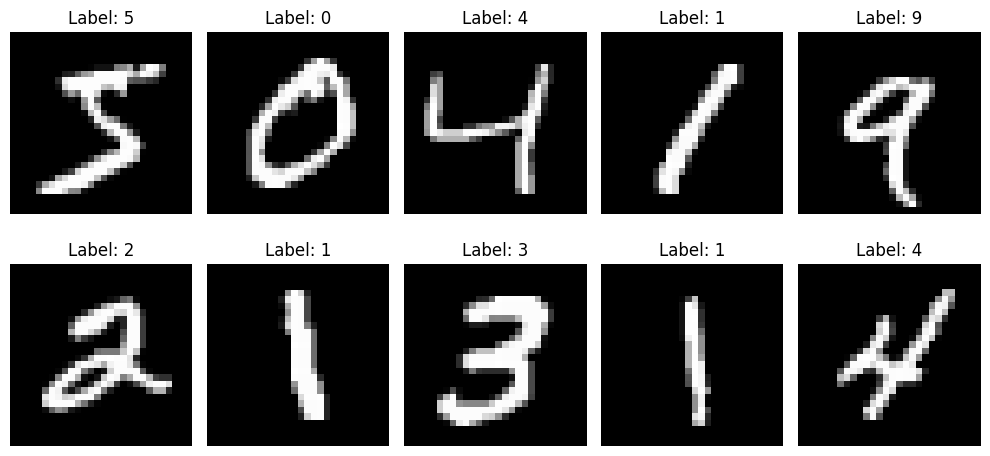

In [7]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Normalize pixel values

x_train = x_train / 255.0
x_test = x_test / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9226 - loss: 0.2724 - val_accuracy: 0.9688 - val_loss: 0.1204
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9651 - loss: 0.1174 - val_accuracy: 0.9738 - val_loss: 0.0893
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9760 - loss: 0.0811 - val_accuracy: 0.9768 - val_loss: 0.0815
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9814 - loss: 0.0606 - val_accuracy: 0.9788 - val_loss: 0.0753
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9863 - loss: 0.0458 - val_accuracy: 0.9787 - val_loss: 0.0777


In [12]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test
)

print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9762 - loss: 0.0778
Test Accuracy: 97.61999845504761 %


In [13]:
predictions = model.predict(x_test[:10])

predicted_labels = np.argmax(predictions, axis=1)

print("Predicted digits:", predicted_labels)
print("Actual digits:   ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Predicted digits: [7 2 1 0 4 1 4 9 6 9]
Actual digits:    [7 2 1 0 4 1 4 9 5 9]


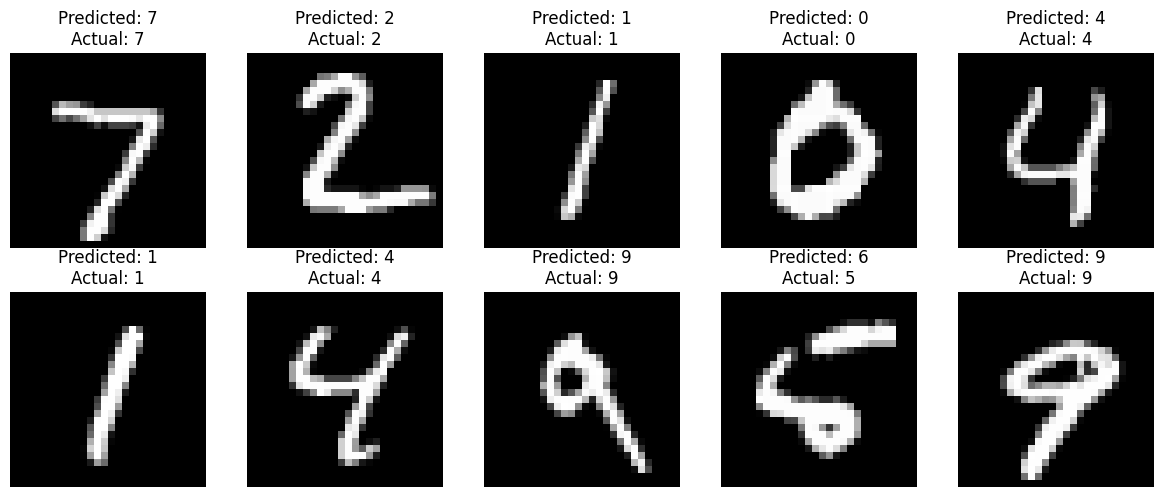

In [14]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap="gray")

    predicted = predicted_labels[i]
    actual = y_test[i]

    plt.title(f"Predicted: {predicted}\nActual: {actual}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
confidence = np.max(predictions, axis=1) * 100

for i in range(10):
    print(
        f"Image {i+1}: Predicted = {predicted_labels[i]}, "
        f"Actual = {y_test[i]}, "
        f"Confidence = {confidence[i]:.2f}%"
    )

Image 1: Predicted = 7, Actual = 7, Confidence = 99.98%
Image 2: Predicted = 2, Actual = 2, Confidence = 99.99%
Image 3: Predicted = 1, Actual = 1, Confidence = 99.81%
Image 4: Predicted = 0, Actual = 0, Confidence = 99.99%
Image 5: Predicted = 4, Actual = 4, Confidence = 99.73%
Image 6: Predicted = 1, Actual = 1, Confidence = 99.97%
Image 7: Predicted = 4, Actual = 4, Confidence = 99.99%
Image 8: Predicted = 9, Actual = 9, Confidence = 98.39%
Image 9: Predicted = 6, Actual = 5, Confidence = 96.01%
Image 10: Predicted = 9, Actual = 9, Confidence = 99.17%


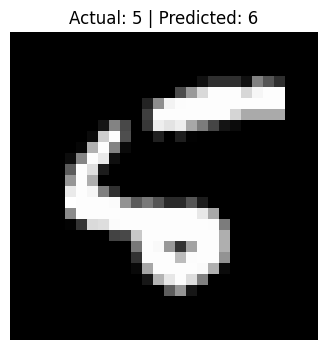

In [16]:
plt.figure(figsize=(4, 4))

plt.imshow(x_test[8], cmap="gray")

plt.title("Actual: 5 | Predicted: 6")
plt.axis("off")

plt.show()

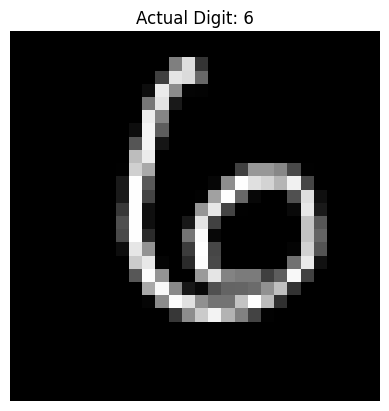

In [33]:
index = 100
plt.imshow(x_test[index], cmap="gray")
plt.title(f"Actual Digit: {y_test[index]}")
plt.axis("off")
plt.show()

In [34]:
single_image = x_test[index:index+1]

prediction = model.predict(single_image, verbose=0)

predicted_digit = np.argmax(prediction)

confidence = np.max(prediction) * 100

print("Actual Digit:", y_test[index])
print("Predicted Digit:", predicted_digit)
print(f"Confidence: {confidence:.2f}%")

Actual Digit: 6
Predicted Digit: 6
Confidence: 100.00%


In [35]:
model.save("handwritten_digit_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [36]:
from google.colab import files

files.download("handwritten_digit_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
loaded_model = tf.keras.models.load_model(
    "handwritten_digit_model.keras"
)

print("Model loaded successfully!")

Model loaded successfully!


In [38]:
index = 100

single_image = x_test[index:index+1]

prediction = loaded_model.predict(single_image, verbose=0)

predicted_digit = np.argmax(prediction)

confidence = np.max(prediction) * 100

print("Actual Digit:", y_test[index])
print("Predicted Digit:", predicted_digit)
print(f"Confidence: {confidence:.2f}%")

Actual Digit: 6
Predicted Digit: 6
Confidence: 100.00%


In [39]:
!pip install -q gradio

In [40]:
import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

print("Gradio version:", gr.__version__)
print("TensorFlow version:", tf.__version__)

Gradio version: 6.30.0
TensorFlow version: 2.21.0


In [41]:
with gr.Blocks() as demo:

    gr.Markdown("# AI Handwritten Digit Recognition")

    gr.Markdown("Draw a digit between 0 and 9.")

    sketch = gr.Sketchpad(
        label="Draw your digit",
        type="numpy",
        image_mode="RGBA",
        height=300,
        width=300
    )

    predict_button = gr.Button("Predict Digit")

    result = gr.Textbox(label="AI Prediction")

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c40cd4796887d21721.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [42]:
def preprocess_image(image):

    # Convert image into NumPy array
    image = np.array(image)

    # Convert RGBA to grayscale
    image = Image.fromarray(image).convert("L")

    # Resize to 28x28
    image = image.resize((28, 28))

    # Convert into NumPy array
    image = np.array(image)

    # Normalize pixel values
    image = image / 255.0

    # Reshape for model input
    image = image.reshape(1, 28, 28)

    return image

In [43]:
def predict_digit(image):

    if image is None:
        return "Please draw a digit first."

    processed_image = preprocess_image(image)

    prediction = loaded_model.predict(
        processed_image,
        verbose=0
    )

    predicted_digit = int(np.argmax(prediction))

    confidence = float(np.max(prediction) * 100)

    return f"Predicted Digit: {predicted_digit} | Confidence: {confidence:.2f}%"

In [44]:
with gr.Blocks() as demo:

    gr.Markdown("# AI Handwritten Digit Recognition")
    gr.Markdown("Draw any digit between 0 and 9.")

    sketch = gr.Sketchpad(
        label="Draw your digit",
        type="numpy",
        image_mode="RGBA",
        height=300,
        width=300
    )

    predict_button = gr.Button("Predict Digit")

    result = gr.Textbox(label="AI Prediction")

    predict_button.click(
        fn=predict_digit,
        inputs=sketch,
        outputs=result
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6d150d2a3eeed0d6cf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [48]:
def debug_image(image):
    print("Input type:", type(image))

    if isinstance(image, dict):
        print("Dictionary keys:", image.keys())

    elif image is not None:
        print("Image shape:", np.array(image).shape)
        print("Image dtype:", np.array(image).dtype)

    return "Debug completed"

In [49]:
with gr.Blocks() as demo:

    gr.Markdown("# Debug Handwritten Digit Recognition")

    sketch = gr.Sketchpad(
        label="Draw your digit",
        type="numpy",
        image_mode="RGBA",
        height=300,
        width=300
    )

    button = gr.Button("Check Image")
    output = gr.Textbox()

    button.click(
        fn=debug_image,
        inputs=sketch,
        outputs=output
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://cd765206f3dd6ae44c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [53]:
def debug_image(image):
    if image is None:
        return "No image received"

    return f"Dictionary keys: {list(image.keys())}"


In [54]:
with gr.Blocks() as demo:

    gr.Markdown("# Debug Handwritten Digit Recognition")

    sketch = gr.Sketchpad(
        label="Draw your digit",
        type="numpy",
        image_mode="RGBA",
        height=300,
        width=300
    )

    button = gr.Button("Check Image")
    output = gr.Textbox()

    button.click(
        fn=debug_image,
        inputs=sketch,
        outputs=output
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://82e9ab5f7d97a4e9c3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [55]:
def debug_image(image):

    if image is None:
        return "No image received"

    composite = image["composite"]

    if composite is None:
        return "Composite image is empty"

    return (
        f"Composite type: {type(composite)}\n"
        f"Composite shape: {np.array(composite).shape}\n"
        f"Composite dtype: {np.array(composite).dtype}"
    )

In [56]:
with gr.Blocks() as demo:

    gr.Markdown("# Debug Handwritten Digit Recognition")

    sketch = gr.Sketchpad(
        label="Draw your digit",
        type="numpy",
        image_mode="RGBA",
        height=300,
        width=300
    )

    button = gr.Button("Check Image")
    output = gr.Textbox()

    button.click(
        fn=debug_image,
        inputs=sketch,
        outputs=output
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8a49432631eb881ce5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [62]:
import gradio as gr
import numpy as np
import tensorflow as tf
from PIL import Image

loaded_model = tf.keras.models.load_model(
    "handwritten_digit_model.keras"
)

In [63]:
def preprocess_image(image):

    # Extract the composite drawing from Gradio
    image = image["composite"]

    # Convert RGBA image to RGB
    pil_image = Image.fromarray(image).convert("RGB")

    # Convert RGB to grayscale
    pil_image = pil_image.convert("L")

    # Convert to NumPy array
    image_array = np.array(pil_image)

    # Check background brightness
    # MNIST expects black background and white digit
    if np.mean(image_array) > 127:
        image_array = 255 - image_array

    # Resize image to 28x28
    pil_image = Image.fromarray(image_array)
    pil_image = pil_image.resize((28, 28))

    # Normalize pixel values
    image_array = np.array(pil_image) / 255.0

    # Prepare input for neural network
    image_array = image_array.reshape(1, 28, 28)

    return image_array

In [64]:
def predict_digit(image):

    if image is None:
        return "Please draw a digit first."

    processed_image = preprocess_image(image)

    prediction = loaded_model.predict(
        processed_image,
        verbose=0
    )

    predicted_digit = int(np.argmax(prediction))

    confidence = float(np.max(prediction) * 100)

    return f"Predicted Digit: {predicted_digit} | Confidence: {confidence:.2f}%"

In [65]:
with gr.Blocks() as demo:

    gr.Markdown("# AI Handwritten Digit Recognition")

    gr.Markdown("Draw a digit between 0 and 9.")

    sketch = gr.Sketchpad(
        label="Draw your digit",
        type="numpy",
        image_mode="RGBA",
        height=300,
        width=300
    )

    predict_button = gr.Button("Predict Digit")

    result = gr.Textbox(label="AI Prediction")

    predict_button.click(
        fn=predict_digit,
        inputs=sketch,
        outputs=result
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2c9383c635dc783335.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
